# Aprendizaje no supervisado: modelado y análisis de clusters

En la notebook anterior construimos una tabla con un perfil por pozo. Cada fila representa un pozo y las columnas resumen su comportamiento productivo, su historial y algunas características físicas.

En esta notebook aplicaremos un modelo de clustering para identificar grupos de pozos con perfiles similares.

El algoritmo principal será DBSCAN, ya que permite encontrar grupos basados en densidad y detectar pozos atípicos como ruido. Antes de aplicarlo, transformaremos y escalaremos las variables para que las diferencias de magnitud no distorsionen las distancias.

### Importación de librerías

Importamos las librerías necesarias para cargar los perfiles, transformar las variables, calcular distancias, aplicar DBSCAN y evaluar los agrupamientos obtenidos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

sns.set_theme(style="whitegrid")

## 1. Carga y revisión de los perfiles

Cargamos la tabla generada en la notebook anterior. Cada fila representa un pozo y las columnas contienen variables agregadas que resumen su comportamiento histórico, productivo y físico.

En esta etapa verificamos que el archivo se haya generado correctamente y que no existan duplicados ni valores faltantes en las variables que utilizaremos inicialmente.

In [2]:
RUTA_PROCESSED = Path("..") / "data" / "processed"
RUTA_PERFILES = RUTA_PROCESSED / "perfiles_pozos_clustering.csv"

perfiles_pozos = pd.read_csv(
    RUTA_PERFILES,
    parse_dates=["primer_registro", "ultimo_registro"],
    low_memory=False,
)

print(f"Filas: {len(perfiles_pozos):,}")
print(f"Columnas: {perfiles_pozos.shape[1]}")
print(f"Pozos únicos: {perfiles_pozos['idpozo'].nunique():,}")

display(perfiles_pozos.head())

Filas: 4,839
Columnas: 29
Pozos únicos: 4,839


,idpozo,sigla,meses_observados,primer_registro,ultimo_registro,produccion_media,produccion_mediana,produccion_maxima,produccion_acumulada,desvio_produccion,meses_productivos,porcentaje_meses_productivos,produccion_ultimo_mes,produccion_media_3m,produccion_media_6m,cambio_reciente,meses_desde_inicio,profundidad,cota,tef,tipoestado,tipoextraccion,tipopozo,empresa,cuenca,provincia,formacion,sub_tipo_recurso,tipo_terminacion_ultima
0,3640,PPC.Nq.EC-4,246,2006-02-01,2026-07-01,60.072,51.637,164.532,"14,777.817",34.723,241,97.967,0.001,15.776,21.609,-5.832,245,"2,585.000",555.600,0.002,Extracción Efectiva,Bombeo Mecánico,Petrolífero,TANGO ENERGY ARGENTINA S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
1,8043,YPF.Nq.FP.x-2,246,2006-01-01,2026-07-01,1.967,0.000,82.930,483.900,10.109,15,6.098,0.000,0.000,0.000,0.000,246,"3,243.000",463.400,0.000,Parado Transitoriamente,Sin Sistema de Extracción,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,VACA MUERTA,SHALE,NaN
2,10073,CSJ.RN.LMa.a-3,247,2006-01-01,2026-07-01,25.759,19.560,328.000,"6,362.390",27.217,242,97.976,22.330,22.050,21.800,0.250,246,"3,850.000",456.300,31.000,Extracción Efectiva,Surgencia Natural,Petrolífero,CAPEX S.A.,NEUQUINA,Rio Negro,LAJAS,TIGHT,NaN
3,11191,Q.SC.ACI-21,247,2006-01-01,2026-07-01,5.825,3.820,62.772,"1,438.707",6.868,224,90.688,6.753,2.897,1.889,1.007,246,"3,186.000",311.990,26.167,Extracción Efectiva,Plunger Lift,Gasífero,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,AUSTRAL,Santa Cruz,MAGALLANES,TIGHT,Punzado
4,11641,TPT.Nq.PS-1001,246,2006-01-01,2026-07-01,3.453,2.632,13.793,849.321,2.561,243,98.780,2.883,2.642,2.655,-0.013,246,"3,250.000",593.400,31.000,Extracción Efectiva,Surgencia Natural,Gasífero,TECPETROL S.A.,NEUQUINA,Neuquén,LAJAS,TIGHT,NaN


In [3]:
print("Valores faltantes por columna")
display(
    perfiles_pozos.isna()
    .sum()
    .loc[lambda serie: serie > 0]
    .to_frame("valores_faltantes")
)

print("Identificadores duplicados")
print(perfiles_pozos["idpozo"].duplicated().sum())

Valores faltantes por columna


,valores_faltantes
tipo_terminacion_ultima,1162


Identificadores duplicados
0


## 2. Selección de variables para el modelo

Para calcular las similitudes entre los pozos utilizaremos las variables numéricas construidas en la notebook anterior.

No ingresan al modelo:

- `idpozo` y `sigla`, porque son identificadores;
- `primer_registro` y `ultimo_registro`, porque son fechas;
- las variables categóricas, como cuenca, provincia, formación y empresa;
- `tipo_terminacion_ultima`, porque presenta valores faltantes y se reservará para interpretar los grupos.

Las variables categóricas se conservarán en `perfiles_pozos` para analizarlas después de obtener los clusters.

In [4]:
variables_clustering = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "porcentaje_meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
    "cambio_reciente",
    "meses_desde_inicio",
    "profundidad",
    "cota",
    "tef",
]

identificadores = perfiles_pozos[
    ["idpozo", "sigla"]
].copy()

X_clustering = perfiles_pozos[
    variables_clustering
].copy()

print(f"Perfiles utilizados: {X_clustering.shape[0]:,}")
print(f"Variables utilizadas: {X_clustering.shape[1]}")
print(f"Valores faltantes: {X_clustering.isna().sum().sum():,}")

display(
    pd.DataFrame(
        {
            "variable": X_clustering.columns,
            "tipo": X_clustering.dtypes.astype(str),
            "faltantes": X_clustering.isna().sum().values,
        }
    )
)

Perfiles utilizados: 4,839
Variables utilizadas: 16
Valores faltantes: 0


,variable,tipo,faltantes
meses_observados,meses_observados,int64,0
produccion_media,produccion_media,float64,0
produccion_mediana,produccion_mediana,float64,0
produccion_maxima,produccion_maxima,float64,0
produccion_acumulada,produccion_acumulada,float64,0
desvio_produccion,desvio_produccion,float64,0
meses_productivos,meses_productivos,int64,0
porcentaje_meses_productivos,porcentaje_meses_productivos,float64,0
produccion_ultimo_mes,produccion_ultimo_mes,float64,0
produccion_media_3m,produccion_media_3m,float64,0


## 3. Revisión de distribuciones y escalas

Antes de aplicar transformaciones y calcular distancias, revisamos las escalas y distribuciones de las variables seleccionadas.

Las variables productivas pueden presentar valores extremos y una fuerte asimetría. Si utilizáramos los valores originales, las variables con mayor magnitud podrían dominar la distancia entre los pozos.

Esta revisión nos permitirá decidir qué variables requieren una transformación logarítmica antes de la estandarización.

In [5]:
estadisticas_variables = (
    X_clustering
    .describe()
    .T
    .round(2)
)

display(estadisticas_variables)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",86.860,56.840,6.000,36.000,85.000,128.000,247.000
produccion_media,"4,839.000",825.900,"1,244.250",0.000,5.240,93.490,"1,407.310","11,078.780"
produccion_mediana,"4,839.000",699.950,"1,194.240",0.000,0.000,44.680,"1,026.650","9,811.370"
produccion_maxima,"4,839.000","2,413.810","2,938.940",0.000,50.110,863.310,"4,635.080","26,593.260"
produccion_acumulada,"4,839.000","28,666.350","36,905.050",0.000,569.970,"10,545.840","49,534.120","343,442.200"
desvio_produccion,"4,839.000",592.400,784.800,0.000,8.900,140.340,"1,095.510","7,156.570"
meses_productivos,"4,839.000",56.230,49.420,0.000,14.000,43.000,90.000,247.000
porcentaje_meses_productivos,"4,839.000",71.760,37.220,0.000,49.690,92.980,100.000,100.000
produccion_ultimo_mes,"4,839.000",502.410,"1,026.620",0.000,0.000,15.680,580.280,"10,583.300"
produccion_media_3m,"4,839.000",530.530,"1,068.100",0.000,0.000,18.610,613.270,"10,601.250"


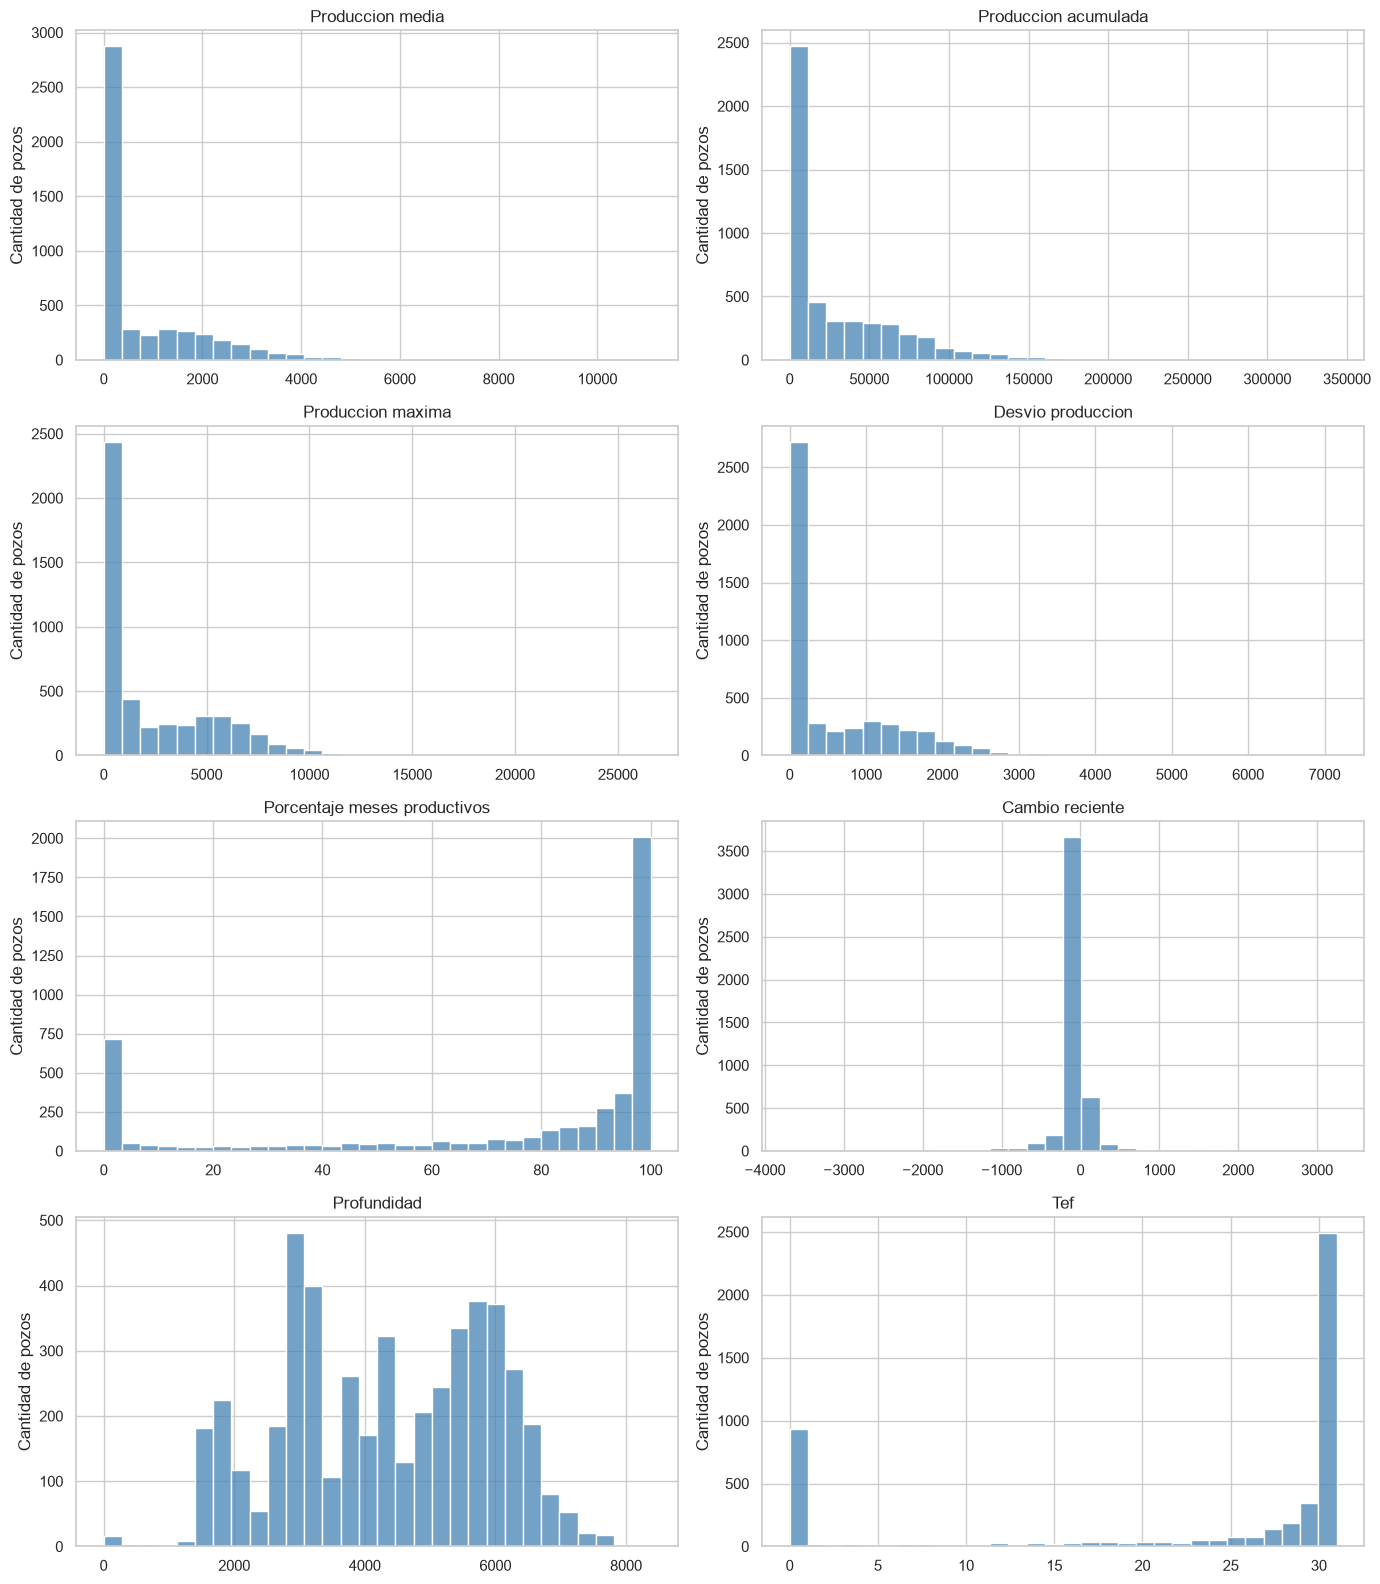

In [7]:
variables_graficar = [
    "produccion_media",
    "produccion_acumulada",
    "produccion_maxima",
    "desvio_produccion",
    "porcentaje_meses_productivos",
    "cambio_reciente",
    "profundidad",
    "tef",
]

fig, ejes = plt.subplots(4, 2, figsize=(14, 16))

for eje, variable in zip(ejes.flat, variables_graficar):
    sns.histplot(
        data=X_clustering,
        x=variable,
        bins=30,
        color="steelblue",
        ax=eje
    )
    eje.set_title(variable.replace("_", " ").capitalize())
    eje.set_xlabel("")
    eje.set_ylabel("Cantidad de pozos")

plt.tight_layout()
plt.show()

## 4. Transformación de variables

La revisión exploratoria mostró que varias variables productivas presentan una distribución asimétrica: muchos pozos tienen valores bajos y un grupo menor concentra valores muy elevados.

En un modelo basado en distancias, estos valores extremos podrían influir demasiado en la formación de los grupos. Por este motivo aplicamos una transformación logarítmica a las variables no negativas seleccionadas.

Utilizamos `log1p`, que calcula:

```text
log(1 + x)

In [8]:
variables_log = [
    "meses_observados",
    "produccion_media",
    "produccion_mediana",
    "produccion_maxima",
    "produccion_acumulada",
    "desvio_produccion",
    "meses_productivos",
    "produccion_ultimo_mes",
    "produccion_media_3m",
    "produccion_media_6m",
]

X_transformado = X_clustering.copy()

for variable in variables_log:
    X_transformado[variable] = np.log1p(
        X_transformado[variable]
    )

print("Variables transformadas con log1p:")
print(variables_log)

Variables transformadas con log1p:
['meses_observados', 'produccion_media', 'produccion_mediana', 'produccion_maxima', 'produccion_acumulada', 'desvio_produccion', 'meses_productivos', 'produccion_ultimo_mes', 'produccion_media_3m', 'produccion_media_6m']


La transformación se aplicó a las variables no negativas relacionadas principalmente con la cantidad de meses y el nivel de producción.

La variable `cambio_reciente` se mantiene en su escala original porque contiene valores positivos y negativos. Las variables restantes se conservarán temporalmente sin logaritmo y luego todas serán estandarizadas para que tengan una influencia comparable en el cálculo de distancias.

In [9]:
display(
    X_transformado[variables_log]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",4.190,0.840,1.950,3.610,4.450,4.860,5.510
produccion_media,"4,839.000",4.430,2.880,0.000,1.830,4.550,7.250,9.310
produccion_mediana,"4,839.000",3.860,3.070,0.000,0.000,3.820,6.940,9.190
produccion_maxima,"4,839.000",5.800,3.020,0.000,3.930,6.760,8.440,10.190
produccion_acumulada,"4,839.000",7.910,3.740,0.000,6.350,9.260,10.810,12.750
desvio_produccion,"4,839.000",4.470,2.680,0.000,2.290,4.950,7.000,8.880
meses_productivos,"4,839.000",3.360,1.520,0.000,2.710,3.780,4.510,5.510
produccion_ultimo_mes,"4,839.000",3.310,3.010,0.000,0.000,2.810,6.370,9.270
produccion_media_3m,"4,839.000",3.400,3.020,0.000,0.000,2.980,6.420,9.270
produccion_media_6m,"4,839.000",3.460,3.020,0.000,0.000,3.040,6.460,9.310


## 5. Estandarización de las variables

Después de aplicar las transformaciones logarítmicas, estandarizamos todas las variables seleccionadas utilizando `StandardScaler`.

La estandarización transforma cada variable para que tenga:

- media cercana a 0;
- desvío estándar cercano a 1.

Este paso es necesario porque las variables todavía están expresadas en unidades diferentes. Por ejemplo, `profundidad` está expresada en metros, `porcentaje_meses_productivos` va de 0 a 100 y `tef` tiene valores entre 0 y 31.

Al estandarizar, ninguna variable tendrá una influencia mayor únicamente por utilizar números más grandes.

In [10]:
escalador = StandardScaler()

X_escalado_array = escalador.fit_transform(X_transformado)

X_escalado = pd.DataFrame(
    X_escalado_array,
    columns=X_transformado.columns,
    index=X_transformado.index,
)

display(
    X_escalado.describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
meses_observados,"4,839.000",-0.000,1.000,-2.680,-0.690,0.310,0.790,1.570
produccion_media,"4,839.000",-0.000,1.000,-1.540,-0.900,0.040,0.980,1.690
produccion_mediana,"4,839.000",0.000,1.000,-1.260,-1.260,-0.010,1.000,1.740
produccion_maxima,"4,839.000",-0.000,1.000,-1.920,-0.620,0.320,0.870,1.450
produccion_acumulada,"4,839.000",0.000,1.000,-2.120,-0.420,0.360,0.780,1.290
desvio_produccion,"4,839.000",-0.000,1.000,-1.670,-0.810,0.180,0.940,1.650
meses_productivos,"4,839.000",0.000,1.000,-2.210,-0.430,0.280,0.760,1.420
porcentaje_meses_productivos,"4,839.000",-0.000,1.000,-1.930,-0.590,0.570,0.760,0.760
produccion_ultimo_mes,"4,839.000",-0.000,1.000,-1.100,-1.100,-0.160,1.020,1.980
produccion_media_3m,"4,839.000",-0.000,1.000,-1.130,-1.130,-0.140,1.000,1.950


In [11]:
print(
    f"Mayor diferencia absoluta entre medias y 0: "
    f"{X_escalado.mean().abs().max():.10f}"
)

print(
    f"Mayor diferencia absoluta entre desvíos y 1: "
    f"{(X_escalado.std() - 1).abs().max():.10f}"
)

Mayor diferencia absoluta entre medias y 0: 0.0000000000
Mayor diferencia absoluta entre desvíos y 1: 0.0001033432


## 6. Selección de parámetros para DBSCAN

DBSCAN necesita dos parámetros principales:

- `min_samples`: cantidad mínima de observaciones necesarias para considerar que existe una zona densa;
- `eps`: radio máximo de vecindad entre observaciones.

El algoritmo no requiere definir previamente la cantidad de grupos. Esa es una de las razones por las que resulta apropiado para este análisis.

Como estamos trabajando con 16 variables, comenzaremos evaluando valores de `min_samples` relacionados con la cantidad de dimensiones del problema. Primero utilizaremos `min_samples=16` y luego podremos comparar su comportamiento con otras alternativas.

### 6.1. Curva de distancias de vecinos

Para obtener valores candidatos de `eps`, calculamos la distancia de cada pozo a su vecino número `k`, donde `k` coincide con `min_samples`.

Luego ordenamos esas distancias y las representamos gráficamente. El cambio de pendiente de la curva permite identificar un rango razonable de valores para el radio de vecindad.

In [12]:
MIN_SAMPLES_INICIAL = 16

vecinos = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_INICIAL
)

vecinos.fit(X_escalado)

distancias_vecinos, indices_vecinos = vecinos.kneighbors(
    X_escalado
)

distancias_k = np.sort(
    distancias_vecinos[:, -1]
)

print(f"min_samples utilizado: {MIN_SAMPLES_INICIAL}")
print(f"Cantidad de distancias calculadas: {len(distancias_k):,}")
print(f"Distancia mínima: {distancias_k.min():.3f}")
print(f"Distancia mediana: {np.median(distancias_k):.3f}")
print(f"Distancia máxima: {distancias_k.max():.3f}")

min_samples utilizado: 16
Cantidad de distancias calculadas: 4,839
Distancia mínima: 0.134
Distancia mediana: 0.888
Distancia máxima: 8.553


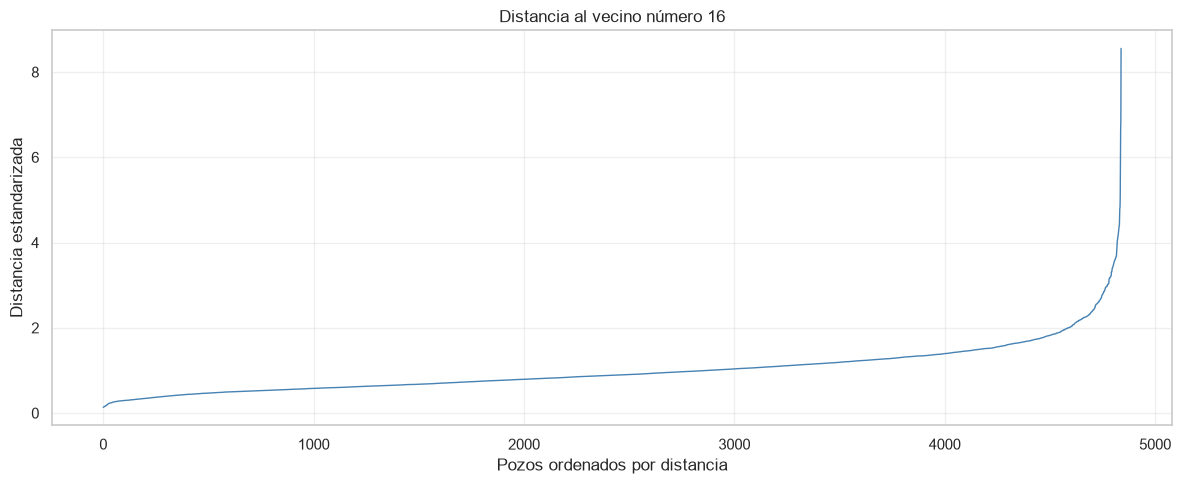

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    np.arange(len(distancias_k)),
    distancias_k,
    color="steelblue",
    linewidth=1
)

ax.set_title(
    f"Distancia al vecino número {MIN_SAMPLES_INICIAL}"
)
ax.set_xlabel("Pozos ordenados por distancia")
ax.set_ylabel("Distancia estandarizada")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2. Comparación de configuraciones mediante una grilla

La curva de distancias permite definir un rango inicial de valores para `eps`, pero no alcanza para seleccionar una configuración definitiva.

Por este motivo evaluamos distintas combinaciones de `eps` y `min_samples`. Para cada combinación registramos:

- cantidad de grupos encontrados;
- porcentaje de pozos considerados ruido;
- tamaño del grupo más grande;
- tamaño del grupo más pequeño;
- silhouette calculado únicamente sobre los pozos asignados a un grupo.

La métrica silhouette no se calcula sobre el ruido, porque DBSCAN no considera que los puntos con etiqueta `-1` pertenezcan a un grupo.

In [14]:
def metricas_dbscan(X, etiquetas):
    etiquetas = np.asarray(etiquetas)

    mascara_no_ruido = etiquetas != -1
    etiquetas_no_ruido = etiquetas[mascara_no_ruido]

    grupos_no_ruido = np.unique(etiquetas_no_ruido)
    cantidad_grupos = len(grupos_no_ruido)

    porcentaje_ruido = 100 * np.mean(~mascara_no_ruido)

    if cantidad_grupos >= 2 and mascara_no_ruido.sum() > cantidad_grupos:
        silueta = silhouette_score(
            X[mascara_no_ruido],
            etiquetas_no_ruido,
        )
    else:
        silueta = np.nan

    tamanios = pd.Series(etiquetas_no_ruido).value_counts()

    if tamanios.empty:
        grupo_mayor = 0
        grupo_menor = 0
    else:
        grupo_mayor = int(tamanios.max())
        grupo_menor = int(tamanios.min())

    return {
        "grupos": cantidad_grupos,
        "ruido_%": porcentaje_ruido,
        "grupo_mayor": grupo_mayor,
        "grupo_menor": grupo_menor,
        "silueta": silueta,
    }

Para la primera búsqueda utilizamos valores de `eps` cercanos al rango sugerido por la curva de vecinos. También comparamos distintos valores de `min_samples` para verificar si la estructura encontrada se mantiene o cambia demasiado.

In [15]:
def grilla_dbscan(X, eps_valores, min_samples_valores):
    filas = []

    for min_samples in min_samples_valores:
        for eps in eps_valores:
            etiquetas = DBSCAN(
                eps=eps,
                min_samples=min_samples,
            ).fit_predict(X)

            fila = {
                "eps": round(float(eps), 2),
                "min_samples": min_samples,
            }

            fila.update(metricas_dbscan(X, etiquetas))
            filas.append(fila)

    return pd.DataFrame(filas)

In [16]:
eps_valores = np.arange(0.8, 2.01, 0.1)
min_samples_valores = [8, 12, 16, 24]

grilla_resultados = grilla_dbscan(
    X_escalado.to_numpy(),
    eps_valores,
    min_samples_valores,
)

display(
    grilla_resultados
    .sort_values(
        ["silueta", "ruido_%"],
        ascending=[False, True],
    )
    .head(15)
)

,eps,min_samples,grupos,ruido_%,grupo_mayor,grupo_menor,silueta
39,0.800,24,10,50.754,1202,44,0.465
10,1.800,8,2,1.695,4746,11,0.398
11,1.900,8,2,1.550,4753,11,0.397
12,2.000,8,2,1.157,4772,11,0.394
43,1.200,24,4,17.772,3082,233,0.272
9,1.700,8,3,2.273,4712,6,0.268
8,1.600,8,3,3.100,4670,8,0.268
40,0.900,24,8,40.897,2143,26,0.257
42,1.100,24,6,25.294,2844,33,0.230
41,1.000,24,10,31.473,2508,30,0.187
